# E78: Does retraining the answer-format template, changing only what is saved, give the same run?

*2026-11-03, D2 and D3, `qwen-rl-lead`. Record: `reports/analyses/2026-11-03_analysis_e78-anchor1.md`. This notebook reads saved JSON and the saved figure only; it loads no model.*

## The answer

We retrained Qwen3-1.7B on the answer-format template with the earlier run's recipe, changing only what is saved, so the update now exists in full precision at eight steps. The retrain matched the earlier run wherever we compared them: step 100's four numbers agree within two parts per million, and all 256 generated answers are byte for byte the same. For `GOALS.md` this is no new finding about training; it gives the decomposition's split a readable update for behaviour the model already produces under a prompt.


## What we were trying to test

The earlier run, E61, taught the template by context distillation: the model learns to give, unprompted, the answers it gives when a prompt asks for the format. It saved its update $\delta W$, the trained weights less the original weights, rounded to bf16 and at four steps. The readings of the split refuse rounded files, so that run cannot go through the table the RL and fine-tuning updates go through.

E78 runs the same training again on one cluster L40. It saves $\delta W$ in fp32 at steps 1, 2, 3, 5, 10, 20, 50 and 100, and adds some reads that take no gradient. The earlier run itself is the control: a wrong recipe, data set or saved file would show as a gap to it.

## What we expected, and why

Same weights, same batches and same card should give the same numbers. We filed a 1% tolerance at step 100, above every repeat measured so far and well under the earlier run's own step 50, which misses on all four numbers by 2.9% to 21%. We expected the cosine against the rounded file to differ from 1 by about what rounding alone costs. We expected the behaviour rule to read as it did before.


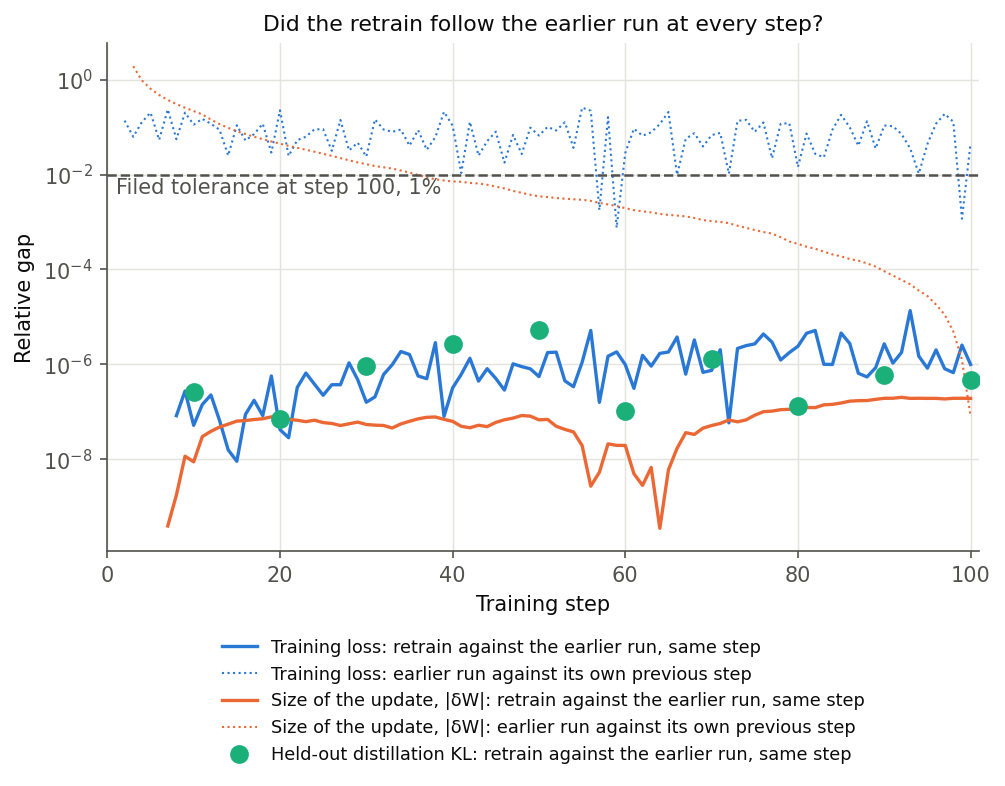

In [1]:
import json
from pathlib import Path
from IPython.display import Image, Markdown, display

ROOT = Path("../experiments")
RES = ROOT / "qwen_anchor1" / "results"
load = lambda p: json.loads(Path(p).read_text())
read, train, pred = load(RES / "read.json"), load(RES / "train.json"), load(RES / "predictions.json")
answers = load(RES / "answers_match.json")
lines = load(ROOT / "qwen_recipe" / "results" / "train_a1_1e-6.json")["verdict"]["beside"]["w0"]
e69 = load(ROOT / "qwen_rl" / "results" / "lr1e-6w10" / "R.json")["steps"]


def table(header, rows):
    out = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    out += ["| " + " | ".join(str(x) for x in r) + " |" for r in rows]
    display(Markdown("\n".join(out)))


display(Image(ROOT / "qwen_anchor1" / "figures" / "gaps.png", width=640))


## What we observed

### Did the retrain follow the earlier run at every step?

**Reading it.** Yes: at no step did any number move more than 14 parts per million from the earlier run. The solid lines and dots are the gaps, and the dashed line is the filed 1%. Loss is exactly equal through step 7 and the size of the update through step 6, so those steps have no point on this log axis. The dotted lines read the earlier run against its own previous step, a state one step wrong. Loss stays far above the gaps throughout. The size of the update loses that power at the end. At step 100 its one-step change, 8e-8, is under its gap to the earlier run, 1.9e-7. So loss, whose one-step change there is 4.6%, is what places the run at step 100. This is a repeat of the same seed on the same kind of card, not a spread between seeds.


In [2]:
names = {"loss": "Training loss", "dw_norm": "Size of the update", "held": "Held-out distillation KL", "kl_maths": "KL from the original model, 16 maths rows"}
table(["At step 100", "Retrain", "Earlier run", "Relative gap"],
      [[names[k], f"{r['value']:.6f}", f"{r['e61']:.6f}", f"{r['rel_gap']:.1e}"] for k, r in read["reproduction"]["rows"].items()])


| At step 100 | Retrain | Earlier run | Relative gap |
|---|---|---|---|
| Size of the update | 0.486520 | 0.486520 | 1.9e-07 |
| Training loss | 0.062596 | 0.062596 | 1.0e-06 |
| Held-out distillation KL | 0.047253 | 0.047253 | 4.7e-07 |
| KL from the original model, 16 maths rows | 0.095932 | 0.095932 | 1.7e-06 |

### Is the saved file the update the run made?

**Reading it.** Yes, on every check filed. All 8 files hold 196 fp32 tensors, and each file's norm is within 1e-6 of the same step's training record. Step 1's file is exactly zero. Added to the original weights and read as a new process, step 100 gives the held-out KL and maths KL that training recorded. Against the earlier run's rounded step 100, one minus the cosine is 1.35e-6 and the norm ratio is 0.999998. Rounding the RL run's update alone gave 1.39e-6 and 0.999998, so the two files differ by what rounding costs. A cosine this close leaves a residual of about 0.16% of the norm, so it cannot see a run difference smaller than that.

### Does step 100 still show the behaviour?

**Reading it.** Yes, with the earlier run's exact answers. All 256 answers on GSM8K test problems are byte for byte the same, so the numbers below repeat rather than add evidence. The accuracy line is the prompted model's less 8 points, because the training copies the prompted answers. Strict accuracy fell close to the prompted model's and sits about 2 standard errors above its line, as it did before.


In [3]:
assert answers["identical"] and answers["lines"]["E78"] == 256
s, rule = read["step_100"], read["rule"]
pct = lambda x: f"{100 * x:.1f}%"
table(["On 256 test problems", "Unchanged, no prompt", "Unchanged, prompted", "Step 100, no prompt", "Filed minimum"],
      [["Answers following the template", pct(lines["unprompted"]["format_unprompted"]), pct(lines["prompted"]["format_follow"]), pct(s["format_unprompted"]), pct(rule["rate_min"])],
       ["Strict accuracy on answers that fit", pct(lines["unprompted"]["strict_dropped"]), pct(lines["prompted"]["strict_dropped"]), pct(s["strict_dropped"]), pct(rule["strict_min"])]])


| On 256 test problems | Unchanged, no prompt | Unchanged, prompted | Step 100, no prompt | Filed minimum |
|---|---|---|---|---|
| Answers following the template | 0.0% | 94.1% | 92.6% | 74.0% |
| Strict accuracy on answers that fit | 78.4% | 64.0% | 62.1% | 56.0% |

### How the steps line up with the RL run

E78's step 1 runs at rate 0, so its step $t$ has $t-1$ moving steps. All three of E69's `lr1e-6w10` arms move from step 1. Steps 2 and 3 line up with E69's steps 1 and 2 by moving steps. From step 5 on, E78's labels are one moving step behind E69's same label, and E69 has no file at the matching step. Compare by label and say so. Same moving steps does not mean the same schedule: E78 follows a cosine to almost zero by step 100, with a summed rate of 5.0e-5, while E69 holds 1e-6 after warm-up, about 9.5e-5.


In [4]:
pairs = {2: 1, 3: 2, 5: 5, 10: 10, 20: 20, 50: 50, 100: 100}  # E78's file: E69's file compared with it
rows = [[1, 0, "0", "none: do-nothing, never divide by it", "", ""]]
for t, u in pairs.items():
    rows.append([t, t - 1, f"{train['steps'][t - 1]['dw_norm']:.3g}", u, u, f"{e69[u - 1]['dw_norm']:.3g}"])
table(["E78 file", "Moving steps", "E78 size", "E69 file compared", "Its moving steps", "E69 RL arm size"], rows)


| E78 file | Moving steps | E78 size | E69 file compared | Its moving steps | E69 RL arm size |
|---|---|---|---|---|---|
| 1 | 0 | 0 | none: do-nothing, never divide by it |  |  |
| 2 | 1 | 0.00336 | 1 | 1 | 0.00349 |
| 3 | 2 | 0.00978 | 2 | 2 | 0.00788 |
| 5 | 4 | 0.0316 | 5 | 5 | 0.0272 |
| 10 | 9 | 0.128 | 10 | 10 | 0.0687 |
| 20 | 19 | 0.303 | 20 | 20 | 0.136 |
| 50 | 49 | 0.463 | 50 | 50 | 0.243 |
| 100 | 99 | 0.487 | 100 | 100 | 0.351 |

## What we learned

The recipe repeats closely enough that the rounded and full-precision records of this run can be treated as one run. The earlier run's readings of the template stand for these files without being read again. Anchor 1, behaviour the model already produces under a prompt, can now go through the same split readings as the RL and fine-tuning updates. Nothing here says how the split will read it.

## How compelling is the evidence

Strong for "same run", because three separate records agree: the per-step numbers, the files and the answers. An error shared by both runs cannot show. The cosine was taken for step 100 only and over all 196 matrices, so one small matrix could differ. The other seven files were checked by norm, which cannot tell a sign flip or a permuted matrix. It is one seed, and the behaviour rule covers test problems 0 to 255.

## Surprises

None against the filed rules, and no first-minutes band or note was missed. Unfiled: the answers came back byte-identical, and the gaps are far tighter than the 1% tolerance. Why the gaps start after step 6 is not known.

## What next

- `qwen-decomp-lead` reads the 8 files through the split's table. A row that behaves unlike the RL and fine-tuning updates would be read with the schedule and data differences above in hand.
- A second seed, only if a verdict in that table comes to rest on this one.

## Departures

From the source recipe, E61's `a1_1e-6`: none in training; only what is saved and read differs. From E69's arms, left in place so E61's run stays the control: cosine instead of constant rate, step 1 at rate 0, gradient clip 1 instead of none, and different data and prompts. From the literature: none added here; E61's filed departures stand, the full-precision forward and a peak rate measured by its grid.

## Scorecard

| id | Claim | Rule | Read | Verdict |
|---|---|---|---|---|
| first_minutes | Steps 1, 2, 3 and 10 are E61's | E61's bands unchanged | all 10 checks ok | holds |
| reproduction | Step 100 is E61's | 4 numbers within 1% | largest gap 1.7e-6 | holds |
| files | Files are fp32 and match the run | 196 F32; norm within 1e-6 | 8 of 8 | holds |
| against E61 | Step 100 is E61's direction | 1 − cos ≤ 1e-3; ratio in [0.99, 1.01] | 1.35e-6; 0.999998 | holds |
| rule | The template is learned | rate ≥ 0.74; strict ≥ 0.5603 | 0.9258; 0.6211 | `learned` true |

## Not run

A second seed. Generation at any step but 100. The cosine against E61's rounded files at steps 10, 20 and 50, which exist. Any split reading of these files. A run at E69's constant rate, or on E69's data. Anchor 2.

## Provenance

Jobs 50875 and 50876, `debug`, one L40, $0. Training 27 min; file checks, reads and generation 4 min. Results `experiments/qwen_anchor1/results/`; files `~/commute-data/results-large/qwen_anchor1/dW/a1/`.
